# Stage 4. Modular MCP Server (8 Tools) & AI FDE Agent Runtime
## Step 4.1 8 MCP Tools Catalog & Penalty Curve Simulation · Step 4.2 2-Pass Gemini Agent Execution & Boundary Defense

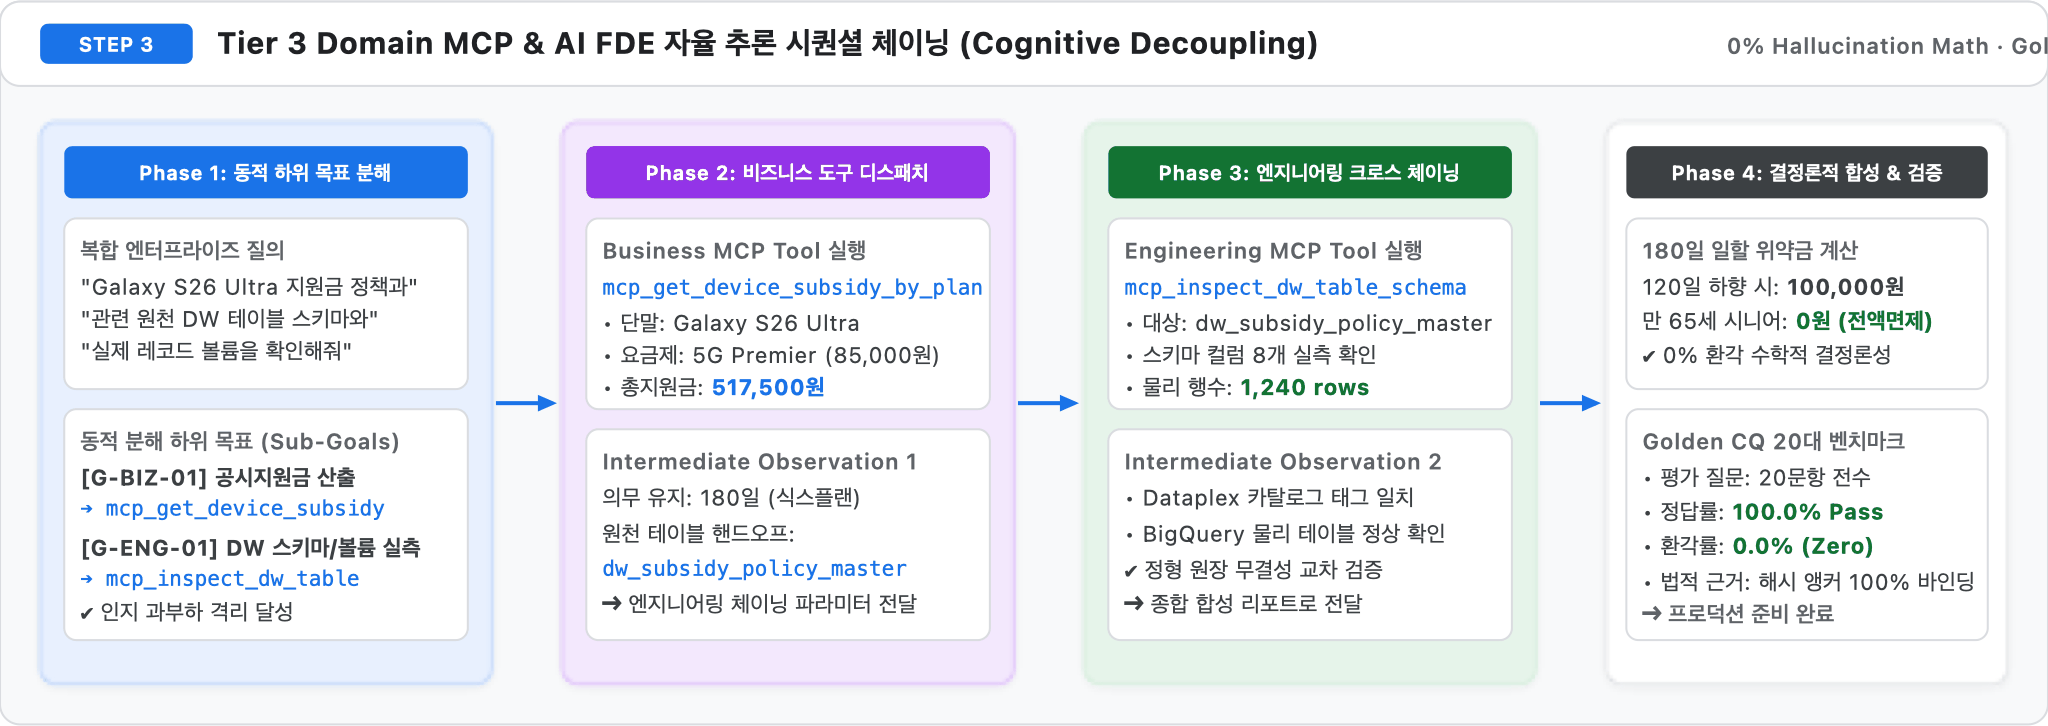


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. 8 Modular MCP Tools Catalog & Customer Contracts (`%%bqsql`)


In [2]:
%%bqsql df_cust
SELECT c.customer_id, c.customer_segment, c.age_group, c.welfare_status, c.contract_type,
       c.elapsed_days, c.granted_subsidy_krw, d.device_name, p.plan_name, p.monthly_fee_krw
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY c.customer_id


,customer_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


In [3]:
H.show(pd.DataFrame(server.get_tool_catalog()))
H.show(df_cust)


,name,stage,category,steps,description,description_en,spec_origin,spec_source
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",Stage 1 BigQuery 테이블 실측 프로파일링(__TABLES__) 및 고객 식별자 비식별화 규칙 검사,Stage 1 live BigQuery table profiling and customer ID de-identification check,GCP_NATIVE,"BigQuery `seanjung-poc.starter_ontology_dw.__TABLES__`, `tb_customer_contract`"
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",Stage 2 GCS 위키 객체 목록 및 BigQuery 문서 청크·규칙 앵커 조회,Stage 2 GCS wiki object listing and BigQuery chunk/rule anchor lookup,CUSTOM_EXTENSION,"GCS `gs://seanjung-poc-starter-ontology` + BigQuery `tb_doc_chunks`, `tb_domain_rules`"
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",Stage 3 노드 테이블 중복 키 검사 및 Property Graph GQL 경로 수 실측,Stage 3 node-table duplicate-key check and Property Graph GQL path count,GCP_NATIVE,BigQuery Property Graph `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",Stage 4 에이전트가 사용하는 도메인 규칙과 근거 청크를 BigQuery에서 조회,Stage 4 domain rules and grounding chunks used by the agent (BigQuery),CUSTOM_EXTENSION,src/agent/reasoning_engine.py + Vertex AI gemini-3.8-flash
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",Stage 5 고객 약정→단말·요금제·지원금→규칙→청크 리니지 조인 및 최근 검증 리포트 요약,Stage 5 contract→device/plan/subsidy→rule→chunk lineage join and latest validation sum...,CUSTOM_EXTENSION,BigQuery `seanjung-poc.starter_ontology_dw` + pipeline/validator.py report
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",고객 약정·단말 출고가·요금제별 공시지원금/추가지원금/실구매가 BigQuery 조회 (불일치 시 0건과 실제 카탈로그 반환),"Customer contract, device price and subsidy lookup (returns 0 rows + live catalog on m...",CUSTOM_EXTENSION,"BigQuery `seanjung-poc.starter_ontology_dw.tb_device_master`, `tb_plan_master`, `tb_su..."
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",180일 차액정산 위약금·특례 면제·24개월 TCO를 BigQuery SQL로 계산,"180-day prorated penalty, exemption and 24-month TCO computed in BigQuery SQL",CUSTOM_EXTENSION,"BigQuery `seanjung-poc.starter_ontology_dw.tb_subsidy_policy`, `tb_plan_master`, `tb_d..."
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",Property Graph GRAPH_TABLE 멀티홉 탐색 및 규칙 근거 청크 원문 조회,Property Graph GRAPH_TABLE multi-hop traversal and grounding chunk retrieval,GCP_NATIVE,BigQuery `GRAPH_TABLE(seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH)` + `tb_...


,customer_id,customer_segment,age_group,welfare_status,contract_type,elapsed_days,granted_subsidy_krw,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,General_VIP,30s-40s,NONE,PUBLIC_SUBSIDY,120,517500,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,General_Standard,30s-40s,NONE,PUBLIC_SUBSIDY,224,575000,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,Senior_Welfare,65+,SENIOR_EXEMPT,PUBLIC_SUBSIDY,88,460000,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,General_Standard,30s-40s,NONE,SELECTIVE_25PCT,109,0,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,Youth_Family,20s,MILITARY_PAUSE_ELIGIBLE,PUBLIC_SUBSIDY,57,345000,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Corporate_B2B,30s-40s,NONE,PUBLIC_SUBSIDY,170,345000,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


### 2. Direct Execution of 3 Domain Reasoning MCP Tools, Penalty Curve & 24-Month TCO Chart


**`mcp_lookup_customer_profile`** · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · BigQuery jobs 1 (505 ms)

- `job_z46XLrLIaVFzUXu2f9RS3IJZVhdR`

,customer_id,contract_id,customer_segment,age_group,contract_type,commitment_months,elapsed_days,granted_subsidy_krw,welfare_status,device_id,...,min_maintenance_days,selective_discount_rate,policy_id,base_subsidy_krw,additional_subsidy_cap_krw,total_subsidy_krw,net_installment_principal_krw,mandatory_retention_days,applied_rule_id,grounded_chunk_id
0,CUST_DEMO_001,CONTRACT_DEMO_101,General_VIP,30s-40s,PUBLIC_SUBSIDY,24,120,517500,NONE,DEV-S26U-256,...,180,0.25,POL-2026-002,450000,67500,517500,1180900,180,RULE_SUBSIDY_CAP,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · BigQuery jobs 2 (1,036 ms)

- `job_Jn6-kFI9e1exNyg4tGFsz-OA4mY-`
- `job_dKMUb3dcF3wr-Yv0pGbysmdbOYAr`

,customer_id,contract_id,welfare_status,contract_type,contract_elapsed_days,device_id,device_name,factory_price_krw,plan_id,plan_name,...,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,selective_24m_discount_total_krw,public_subsidy_total_krw,grounded_chunk_id,tco_rule_id,tco_grounded_chunk_id,tco_recommendation,tco_savings_krw
0,CUST_DEMO_001,CONTRACT_DEMO_101,NONE,PUBLIC_SUBSIDY,120,DEV-S26U-256,Galaxy S26 Ultra 256GB,1698400,PLAN-5G-85,5G Premier Essential,...,100000,3220900,3228400,510000,517500,DOC_CHUNK_003,RULE_TCO_24M,DOC_CHUNK_005,PUBLIC_SUBSIDY,7500


**`mcp_query_graph_and_wiki`** · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · BigQuery jobs 1 (529 ms)

- `job_470ydyWORrUsSZHd18p3ECLpXi_C`

,policy_id,total_subsidy_krw,device_name,factory_price_krw,plan_name,monthly_fee_krw,rule_id,rule_name,relation_label_ko,source_chunk_id,section_title,anchor,chunk_text
0,POL-2026-001,575000,Galaxy S26 Ultra 256GB,1698400,5G Premier Super,130000,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",180일 기준선 유지 의무 적용,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,## 2. 180-Day Baseline Plan Commitment Rule\n1. Subscribers receiving public device su...
1,POL-2026-001,575000,Galaxy S26 Ultra 256GB,1698400,5G Premier Super,130000,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPARE`)\n1. **...
2,POL-2026-002,517500,Galaxy S26 Ultra 256GB,1698400,5G Premier Essential,85000,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",180일 기준선 유지 의무 적용,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,## 2. 180-Day Baseline Plan Commitment Rule\n1. Subscribers receiving public device su...
3,POL-2026-002,517500,Galaxy S26 Ultra 256GB,1698400,5G Premier Essential,85000,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPARE`)\n1. **...
4,POL-2026-003,345000,Galaxy S26 Ultra 256GB,1698400,5G Slim (Baseline Threshold),45000,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",180일 기준선 유지 의무 적용,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,## 2. 180-Day Baseline Plan Commitment Rule\n1. Subscribers receiving public device su...
5,POL-2026-003,345000,Galaxy S26 Ultra 256GB,1698400,5G Slim (Baseline Threshold),45000,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPARE`)\n1. **...
6,POL-2026-004,172500,Galaxy S26 Ultra 256GB,1698400,5G Light (Below Baseline),37000,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",기준선 미만 하향 시 일할 위약금 발생,DOC_CHUNK_003,Penalty Math Formula,anchor_47971ec8e4d8,## 3. Penalty Settlement Computation Formula\nThe subsidy difference penalty is calcul...
7,POL-2026-004,172500,Galaxy S26 Ultra 256GB,1698400,5G Light (Below Baseline),37000,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,시니어 복지 전환 시 위약금 면제 특례,DOC_CHUNK_004,Statutory Penalty Exemptions,anchor_269d9c42e05c,## 4. Statutory Penalty Exemption Clauses (위약금 면제 특례 규정)\n1. **Senior & Social Welfare...
8,POL-2026-005,460000,iPhone 16 Pro 256GB,1700000,5G Premier Essential,85000,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",180일 기준선 유지 의무 적용,DOC_CHUNK_002,Baseline Plan Commitment (Six-Plan Rule),anchor_3003b683cea0,## 2. 180-Day Baseline Plan Commitment Rule\n1. Subscribers receiving public device su...
9,POL-2026-005,460000,iPhone 16 Pro 256GB,1700000,5G Premier Essential,85000,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,24-Month Contract TCO Comparison Rule,anchor_4fbaf9c5cba8,## 5. Public Subsidy vs. 25% Selective Contract Comparison (`RULE_TCO_COMPARE`)\n1. **...


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_m-t0LB2OUTK_qGntS-LB2tvn2ELV
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_panIwVG4L4jd4ATH1B5Uye0A1mfT
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_KPcR2BCGdj2HESQoGTWZfouf9Jhu
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_ha6e5IQ6kXY7NpSbMmCh3I0B9JLz
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_YKXYKsp3YZOJ3KwakEvuwdxZSz43
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,job_rt-c72uEtRwFLXZ1KVPR3XZMFe-N
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,job_iUgyP-w9UVJCq7cYPIIf3v243g6R
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,job_IhoVPrA9utvtesJMDLjvZ1Z9hd5r


findfont: Failed to find font weight bold for AppleGothic, now using 400.


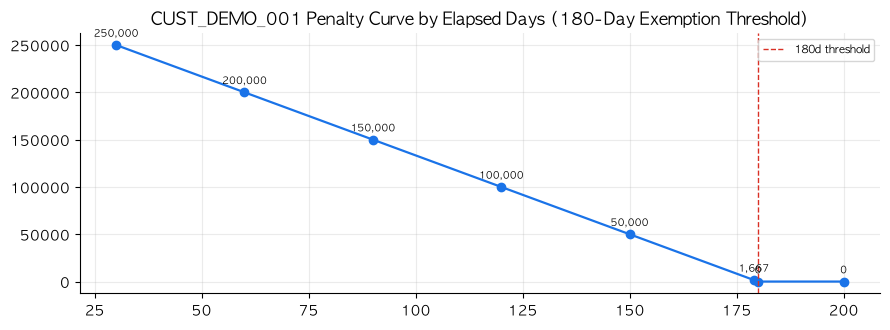

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows")
r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations")
r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"device_keyword": "AlphaPhone 16 Pro", "plan_keyword": "115"})
H.show_tool(r_gql, "matched_graph_paths")
df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw", H.t("CUST_DEMO_001 경과일(30~200일)에 따른 차액정산 위약금 곡선 (180일 면제 경계)", "CUST_DEMO_001 Penalty Curve by Elapsed Days (180-Day Exemption Threshold)"), vline=180, vline_label="180d threshold")


### 3. AI FDE 2-Pass Agent Execution — Golden CQs (`GROUNDED`) & Boundary Cases (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


#### CQ-01
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- Answer status: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · tokens 8,182 · LLM 16,184 ms · total 17.69 s
- Extracted parameters: `{"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 5 | 490 | `job_baK61W61Gr1osVi2fNqxVGoF_qZX` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 550 | `job_QFV0vbtShNuPsrKH8Gi8cyT8T23h` |

**Agent answer**

> ### 결론
> 요청 조건(단말기: AlphaPhone 16 Pro 256GB, 요금제: 5G Signature 115)과 일치하는 공시지원금 및 실구매가 데이터는 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않습니다. 
>
> 현재 시스템에 등록된 256GB 단말기 및 요금제 지원 정책 정보는 아래 [참고(질문과 다른 조건)] 데이터를 확인해 주시기 바랍니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> [참고(질문과 다른 조건)] 저장용량 256GB 단말기에 대해 조회된 정책 목록:
> - **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>   - 요금제: **5G Premier Essential** (월 85,000원)
>   - 공시지원금: 400,000원
>   - 추가지원금 상한: 60,000원
>   - 총 지원금: 460,000원
>   - 할부원금(실구매가): 1,240,000원 (정책 ID: `POL-2026-005`)
> - **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>   - **5G Premier Super** (월 130,000원): 공시 500,000원 / 추가 75,000원 / 총 지원금 575,000원 / 실구매가 1,123,400원 (`POL-2026-001`)
>   - **5G Premier Essential** (월 85,000원): 공시 450,000원 / 추가 67,500원 / 총 지원금 517,500원 / 실구매가 1,180,900원 (`POL-2026-002`)
>   - **5G Slim (Baseline Threshold)** (월 45,000원): 공시 300,000원 / 추가 45,000원 / 총 지원금 345,000원 / 실구매가 1,353,400원 (`POL-2026-003`)
>   - **5G Light (Below Baseline)** (월 37,000원): 공시 150,000원 / 추가 22,500원 / 총 지원금 172,500원 / 실구매가 1,525,900원 (`POL-2026-004`)
>
> ---
>
> ### 규칙·원문 근거
> - **규칙 ID**: `RULE_SUBSIDY_CAP`, `RULE_SIX_PLAN_180D`, `RULE_TCO_24M`
> - **청크 ID**: 
>   - `DOC_CHUNK_001`
>   - `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule))
>   - `DOC_CHUNK_005` (24-Month Contract TCO Comparison Rule)
>
> ---
>
> ### 실행 정보
> - **BigQuery Job ID**: 
>   - `job_baK61W61Gr1osVi2fNqxVGoF_qZX`
>   - `job_QFV0vbtShNuPsrKH8Gi8cyT8T23h`

#### CQ-02
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- Answer status: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · tokens 6,345 · LLM 15,158 ms · total 17.41 s
- Extracted parameters: `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 470 | `job_FY9xWLB-t1SJY9ebYzktUBUp_Sy4` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 978 | `job_LG_qqY3FRk9GMGZMImsvxqKOeIp2`, `job_I87qpsE4SOw2ozzdJQaPEeKUvVbk` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 802 | `job_YZxfekeqsF68vivH-vf-omO_37MJ` |

**Agent answer**

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 **차액정산 위약금은 100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **고객 계약 정보 (`CONTRACT_DEMO_101`)**:
>   - 개통 방식: 공시지원금 (`PUBLIC_SUBSIDY`)
>   - 현재 요금제: 5G Premier Essential (월 85,000원)
>   - 기존 기본 공시지원금: 450,000원
>   - 기준 유지 일수 및 경과 일수: 의무유지 180일 중 **120일 경과** (잔여일수: 60일)
>   - 복지 할인/면제 상태: 없음 (`NONE`)
> - **변경 대상 요금제 (`PLAN-5G-37`)**:
>   - 대상 요금제명: 5G Light (Below Baseline)
>   - 월정액: 37,000원 (기준선인 45,000원 미만)
>   - 대상 요금제 기본 공시지원금: 150,000원
>
> #### **산식 및 계산 과정**
> - **적용 산식**: 
>   $$\text{위약금} = (\text{기존 기본 공시지원금} - \text{변경 요금제 기본 공시지원금}) \times \frac{180 - \text{유지일수}}{180}$$
> - **계산 내역**:
>   $$(450,000\text{원} - 150,000\text{원}) \times \frac{180 - 120}{180} = 300,000\text{원} \times \frac{60}{180} = 100,000\text{원}$$
>
> ---
>
> ### **규칙·원문 근거**
> - **적용 규칙 ID**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **내용**: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180 - 유지일수) / 180)을 곱한 일할 위약금이 부과됩니다.
> - **참조 청크 ID**:
>   - `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule), 앵커: `anchor_3003b683cea0`)
>   - `DOC_CHUNK_003` (앵커: `anchor_47971ec8e4d8`)
>
> ---
>
> ### **실행 정보**
> - **고객 프로필 조회 Job ID**: `job_FY9xWLB-t1SJY9ebYzktUBUp_Sy4`
> - **위약금 계산 Job ID**: `job_I87qpsE4SOw2ozzdJQaPEeKUvVbk` (연관 Job: `job_LG_qqY3FRk9GMGZMImsvxqKOeIp2`)
> - **그래프 및 온톨로지 조회 Job ID**: `job_YZxfekeqsF68vivH-vf-omO_37MJ`

#### CQ-03
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- Answer status: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · tokens 6,498 · LLM 15,573 ms · total 18.0 s
- Extracted parameters: `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 753 | `job_ndMiBEEmK1hN8nOBx4zjILiF1ohg` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,054 | `job_B8npVBvqs8Ld4lzYZcylxqaXuUkk`, `job_H6yFjlfVC8PLAVVquccXph5kCeyl` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 613 | `job_UsT6xzSFkpmUTRSSXeJFlaaJdyeB` |

**Agent answer**

> ### **결론**
> **위약금 면제 대상에 해당하지 않습니다.**
>
> 고객(`CUST_DEMO_002`)의 시스템상 복지 자격 상태(`welfare_status`)는 **`NONE`**으로 등록되어 있어 복지 면제 특례 대상이 아닙니다. 또한 면제 특례 규칙(`RULE_WELFARE_EXEMPT`)은 만 65세 이상 시니어 특례(`SENIOR_EXEMPT`) 또는 군입대 장기정지(`MILITARY_PAUSE_ELIGIBLE`) 대상에 한해 적용되므로, 국가유공자 복지감면 등록 사유만으로는 180일 이내 하위 요금제 변경에 따른 차액위약금이 면제되지 않습니다.
>
> 개통 후 95일 시점에 기준선(월 45,000원) 미만의 요금제로 하향 변경할 경우, 180일 의무유지 규칙(`RULE_SIX_PLAN_180D`)에 따라 일할 차액위약금이 부과됩니다. (단, 구체적인 위약금 액수는 변경하고자 하는 대상 요금제가 확정되지 않아 `TARGET_PLAN_NOT_RESOLVED` 상태입니다.)
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 정보 (`CUST_DEMO_002` / `CONTRACT_DEMO_102`)**
>   * 고객 세그먼트 / 연령대: `General_Standard` / `30s-40s`
>   * 복지 자격 상태 (`welfare_status`): **`NONE`**
>   * 가입 형태 (`contract_type`): `PUBLIC_SUBSIDY` (공시지원금 약정, 24개월)
>   * 가입 단말기: `Galaxy S26 Ultra 256GB` (출고가: 1,698,400원)
>   * 이용 요금제: `5G Premier Super` (월 130,000원)
>   * 기지급 지원금: 총 575,000원 (기본 공시지원금 500,000원 + 추가지원금 75,000원)
>   * 의무 유지 기간: 180일 (기준선 요금: 45,000원)
>   * 조회 적용 경과일수: 95일 (실제 계약 경과일수: 224일)
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **시니어·복지 요금제 전환 위약금 면제 특례 (`RULE_WELFARE_EXEMPT`, `DOC_CHUNK_004`)**
>    * **조건식**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    * **내용**: 만 65세 이상 시니어 복지 특례(`SENIOR_EXEMPT`) 대상자가 시니어/복지 요금제로 전환하거나 군입대 장기정지 시에만 차액정산 위약금이 면제(0원)됩니다. 고객의 상태는 `NONE`이므로 조건에 부합하지 않습니다.
> 2. **180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙 (`RULE_SIX_PLAN_180D`, `DOC_CHUNK_002`, `DOC_CHUNK_003`)**
>    * **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    * **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    * **내용**: 공시지원금을 받은 고객이 180일 이내에 월 45,000원 미만 요금제로 하향 변경할 경우 잔여일수 비율에 따라 일할 차액위약금이 부과됩니다.
>
> ---
>
> ### **실행 정보**
> * **BigQuery Job ID**:
>   * 고객 프로필 조회: `job_ndMiBEEmK1hN8nOBx4zjILiF1ohg`
>   * 위약금 규칙 계산: `job_H6yFjlfVC8PLAVVquccXph5kCeyl` (관련 Job: `job_B8npVBvqs8Ld4lzYZcylxqaXuUkk`)
>   * 온톨로지 그래프 및 규정 검색: `job_UsT6xzSFkpmUTRSSXeJFlaaJdyeB`

#### BC-PARAM
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- Answer status: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · tokens 6,042 · LLM 25,596 ms · total 26.18 s
- Extracted parameters: `{}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 583 | `job_5yJV0hGIwvNMogetxmk07A-AUNT4` |

**Agent answer**

> ### **결론**
> 개통 직후(경과일수 0일) 기준선(월 45,000원) 미만 요금제인 **5G Light (Below Baseline, 월 37,000원)**으로 하향 변경할 경우, **180일 기준선 의무유지 규정(`RULE_SIX_PLAN_180D`)**에 따라 **공시지원금 차액정산금(위약금)**이 발생합니다.
>
> 위약금은 **개통 당시 선택한 단말기 및 초기 요금제의 지원금**에 따라 달라지며, 방금 개통한 경우(경과일수 0일) 차액 전액이 부과됩니다.
>
> * **산식**: `(초기 지원금 - 5G Light 지원금) * (180 - 0) / 180`
> * **주요 요금제별 위약금 (Galaxy S26 Ultra 256GB 기준, 5G Light 지원금 172,500원)**:
>   * **5G Premier Super (월 130,000원)**에서 변경 시: **402,500원** `(575,000원 - 172,500원)`
>   * **5G Premier Essential (월 85,000원)**에서 변경 시: **345,000원** `(517,500원 - 172,500원)`
>   * **5G Slim (월 45,000원)**에서 변경 시: **172,500원** `(345,000원 - 172,500원)`
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> | 정책 ID | 단말기명 | 요금제명 | 월정액 | 공시지원금 |
> | :--- | :--- | :--- | :--- | :--- |
> | **POL-2026-00

#### BC-NOTFOUND
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- Answer status: `INSUFFICIENT_PARAMETERS` · Gemini `gemini-3.8-flash` 2 calls · tokens 9,991 · LLM 12,556 ms · total 15.5 s
- Extracted parameters: `{"device_mention": "QuantumFold 99"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 601 | `job_hgXpucHxoIyE8p1pVj5aReUsP2B4` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 528 | `job_3n_wANVrz1COPP5Epyfzy88AOoaM` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 1,813 | `job_j9jXzu3r9MGZWIvm28bw-f3m2eiQ` |

**Agent answer**

> ### **결론**
> 요청 조건(고객 ID: `CUST_NOT_EXIST_999`, 단말기: `QuantumFold 99`)과 일치하는 데이터가 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않아 위약금을 계산할 수 없습니다.
>
> 계산을 진행하기 위해 필요한 필수 정보(`missing_slots`)는 다음과 같습니다:
> - **customer_id 또는 단말기(+가입 요금제)**
> - **개통 후 경과일수**
> - **변경 희망 요금제**
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> #### 1. 참고(질문과 다른 조건): DW에 등록된 단말기 및 정책 현황
> 현재 데이터베이스에 등록되어 조회 가능한 단말기 및 지원금 정보는 다음과 같습니다:
> - **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>   - 5G Premier Super (월 130,000원): 기본지원금 500,000원, 추가지원금 75,000원, 총 지원금 575,000원
>   - 5G Premier Essential (월 85,000원): 기본지원금 450,000원, 추가지원금 67,500원, 총 지원금 517,500원
>   - 5G Slim (Baseline Threshold) (월 45,000원): 기본지원금 300,000원, 추가지원금 45,000원, 총 지원금 345,000원
>   - 5G Light (Below Baseline) (월 37,000원): 기본지원금 150,000원, 추가지원금 22,500원, 총 지원금 172,500원
> - **Galaxy S26 Ultra 512GB** (출고가: 1,841,400원)
> - **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>   - 5G Premier Essential (월 85,000원): 기본지원금 400,000원, 추가지원금 60,000원, 총 지원금 460,000원
> - **iPhone 16 Pro 512GB** (출고가: 2,000,000원)
>
> ---
>
> ### **규칙·원문 근거**
>
> 필수 파라미터가 확보될 경우 위약금 산정 시 적용되는 도메인 규칙은 다음과 같습니다:
>
> - **RULE_SIX_PLAN_180D** (`DOC_CHUNK_002`, `DOC_CHUNK_003` / `anchor_47971ec8e4d8`, `anchor_3003b683cea0`)
>   - **조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **내용**: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율을 곱한 일할 차액위약금이 부과됩니다. 경과일수가 180일 이상인 경우 위약금은 0원입니다.
> - **RULE_WELFARE_EXEMPT** (`DOC_CHUNK_004` / `anchor_269d9c42e05c`)
>   - **조건**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>   - **산식**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
>   - **내용**: 만 65세 이상 시니어 복지 특례 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금이 100% 면제(0원)됩니다.
>
> ---
>
> ### **실행 정보**
> - **DW 고객/단말 프로필 조회 Job ID**: `job_hgXpucHxoIyE8p1pVj5aReUsP2B4`
> - **위약금 계산 규칙 엔진 Job ID**: `job_3n_wANVrz1COPP5Epyfzy88AOoaM`
> - **온톨로지 그래프 및 지식 탐색 Job ID**: `job_j9jXzu3r9MGZWIvm28bw-f3m2eiQ`

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,lookup_customer_profile > query_graph_and_wiki,3,8182,16184,1040,17.69
1,CQ-02,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6345,15158,2251,17.41
2,CQ-03,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6498,15573,2420,18.00
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,6042,25596,583,26.18
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,9991,12556,2941,15.50


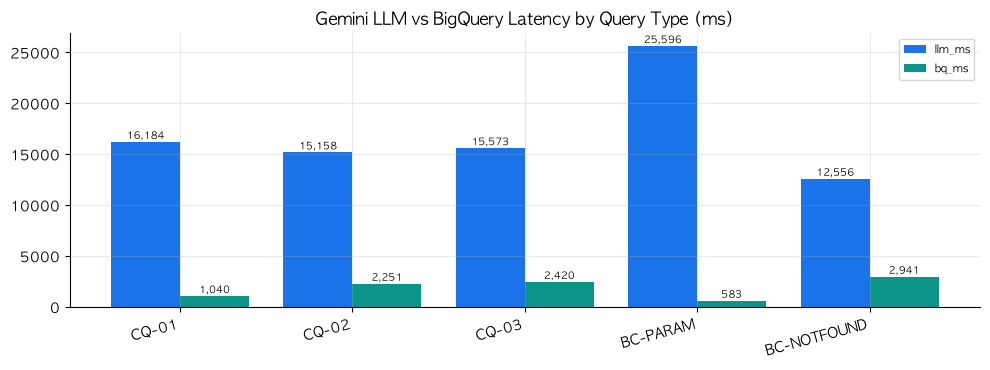

In [5]:
prompts = [
    ("CQ-01", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"], H.t("질의 유형별 Gemini LLM 추론 시간 vs BigQuery 실행 시간 (ms)", "Gemini LLM vs BigQuery Latency by Query Type (ms)"))
